In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from credit_risk import config as C, data as D, features as F, scorecard as S, models as M
from credit_risk import calibration as CAL, business as B, fairness as FAIR, stability as ST
R = lambda s: json.load(open(C.REPORTS / f"metrics_{s}.json"))
def app():
    t = pd.read_parquet(C.ROOT / "data/synthetic/application_train.parquet")  # use data/raw + D.read_table for real data
    return F.engineer_application(D.clean_application(t)), t


# 04 - GBM challenger, imbalance, calibration

In [2]:
m = R('A'); pd.DataFrame(m['imbalance_comparison'])

,strategy,auc,gini,ks,pr_auc,brier,best_iter,mean_pred
0,none,0.687362,0.374725,0.288946,0.177442,0.072047,81,0.078965
1,class_weight,0.691733,0.383465,0.291238,0.181718,0.160113,158,0.339993
2,undersample,0.689952,0.379903,0.275086,0.178179,0.086989,115,0.182889


,method,brier,ece,mean_pred,model
0,raw,0.174966,0.284846,0.366596,LightGBM
1,platt,0.071771,0.008903,0.081280,LightGBM
2,isotonic,0.072354,0.010071,0.081134,LightGBM
3,"scorecard (logistic, raw)",0.072930,0.013929,0.082024,Scorecard


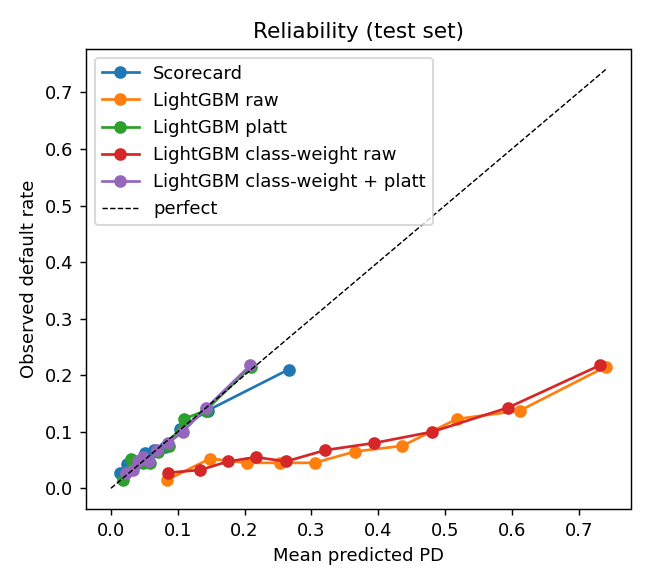

In [3]:
display(pd.DataFrame(m['calibration']['table'])); display(Image(str(C.FIGURES / 'reliability_A.png')))

A class-weighted GBM ranks fine but over-predicts risk (mean PD far above the base rate). Platt/isotonic on the validation set fixes it without changing the ranking.

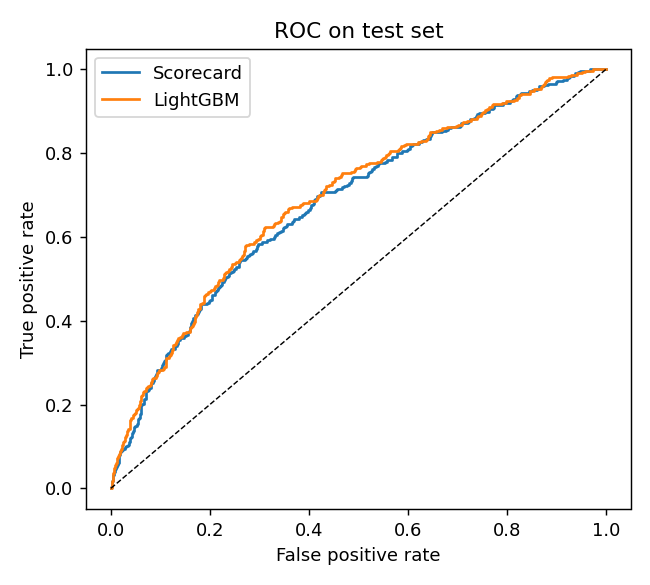

In [4]:
display(Image(str(C.FIGURES / 'roc_A.png')))